## Q3 - Nifty Daily Return Distribution & Hypothesis Discovery

In [1]:
import pandas as pd 
df = pd.read_csv("nifty_daily_data.csv")
df.head(5)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-01-04 00:00:00+05:30,5200.899902,5238.450195,5167.100098,5232.200195,0,0.0,0.0
1,2010-01-05 00:00:00+05:30,5277.149902,5288.350098,5242.399902,5277.899902,0,0.0,0.0
2,2010-01-06 00:00:00+05:30,5278.149902,5310.850098,5260.049805,5281.799805,0,0.0,0.0
3,2010-01-07 00:00:00+05:30,5281.799805,5302.549805,5244.750000,5263.100098,0,0.0,0.0
4,2010-01-08 00:00:00+05:30,5264.250000,5276.750000,5234.700195,5244.750000,0,0.0,0.0


In [2]:
df.shape

(4097, 8)

In [3]:
df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends',
       'Stock Splits'],
      dtype='str')

In [4]:
df.dtypes

Date                str
Open            float64
High            float64
Low             float64
Close           float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

In [5]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes

Date            datetime64[us, UTC+05:30]
Open                              float64
High                              float64
Low                               float64
Close                             float64
Volume                              int64
Dividends                         float64
Stock Splits                      float64
dtype: object

In [6]:
df = df.sort_values("Date").reset_index(drop = True)
df.head(5)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-01-04 00:00:00+05:30,5200.899902,5238.450195,5167.100098,5232.200195,0,0.0,0.0
1,2010-01-05 00:00:00+05:30,5277.149902,5288.350098,5242.399902,5277.899902,0,0.0,0.0
2,2010-01-06 00:00:00+05:30,5278.149902,5310.850098,5260.049805,5281.799805,0,0.0,0.0
3,2010-01-07 00:00:00+05:30,5281.799805,5302.549805,5244.750000,5263.100098,0,0.0,0.0
4,2010-01-08 00:00:00+05:30,5264.250000,5276.750000,5234.700195,5244.750000,0,0.0,0.0


In [7]:
# missing values
df.isna().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [8]:
df["Date"].duplicated().sum()

np.int64(0)

In [9]:
# check OHLC data
print("High < Open :",(df["High"] < df["Open"]).sum())
print("High < Close :",(df["High"] < df["Close"]).sum())
print("Low > Open :",(df["Low"] > df["Open"]).sum())
print("Low > Close :",(df["Low"] > df["Close"]).sum())

High < Open : 0
High < Close : 0
Low > Open : 0
Low > Close : 0


In [10]:
df["daily_returns"] = df["Close"].pct_change()
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,daily_returns
0,2010-01-04 00:00:00+05:30,5200.899902,5238.450195,5167.100098,5232.200195,0,0.0,0.0,NaN
1,2010-01-05 00:00:00+05:30,5277.149902,5288.350098,5242.399902,5277.899902,0,0.0,0.0,0.008734
2,2010-01-06 00:00:00+05:30,5278.149902,5310.850098,5260.049805,5281.799805,0,0.0,0.0,0.000739
3,2010-01-07 00:00:00+05:30,5281.799805,5302.549805,5244.750000,5263.100098,0,0.0,0.0,-0.003540
4,2010-01-08 00:00:00+05:30,5264.250000,5276.750000,5234.700195,5244.750000,0,0.0,0.0,-0.003487


In [11]:
df["daily_returns"].describe(percentiles=[0.01,0.05,0.25,0.50,0.75,0.95,0.99])


count    4096.000000
mean        0.000424
std         0.010360
min        -0.129805
1%         -0.026160
5%         -0.015555
25%        -0.004794
50%         0.000546
75%         0.006053
95%         0.016190
99%         0.026076
max         0.087632
Name: daily_returns, dtype: float64

In [12]:
df["daily_returns"].skew()

np.float64(-0.6636422784841641)

In [13]:
df["daily_returns"].kurt()

np.float64(11.521766184345154)

In [14]:
print("Skewness:", df["daily_returns"].skew())
print("Kurtosis:", df["daily_returns"].kurtosis())

Skewness: -0.6636422784841641
Kurtosis: 11.521766184345154


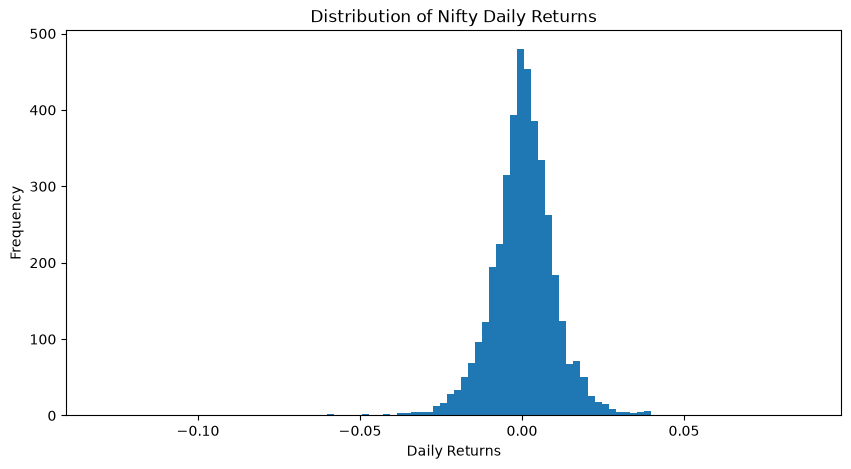

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(df["daily_returns"].dropna(),bins=100)
plt.xlabel("Daily Returns")
plt.ylabel("Frequency")
plt.title("Distribution of Nifty Daily Returns")

plt.show()

Nifty returns have a concentrated centre, negative skew, and pronounced tails.

### Tail Event Counts

In [16]:
lower_1pct = df["daily_returns"].quantile(0.01)
upper_1pct = df["daily_returns"].quantile(0.99)

lower_events = (df["daily_returns"] <= lower_1pct).sum()
upper_events = (df["daily_returns"] >= upper_1pct).sum()


print("1% Lower Tail Threshold:", lower_1pct)
print("1% Lower Tail Events:", lower_events)

print("99% Upper Tail Threshold:", upper_1pct)
print("99% Upper Tail Events:", upper_events)

1% Lower Tail Threshold: -0.026160367979553182
1% Lower Tail Events: 41
99% Upper Tail Threshold: 0.02607576374409573
99% Upper Tail Events: 41


Observation → Extreme returns exist and tails are asymmetric in magnitude.

Candidate research question - 

“Does an extreme Nifty daily return predict a reversal in the next trading day's return?”

In [17]:
df["next_day_return"] = df["daily_returns"].shift(-1)

In [18]:
df[["Date","daily_returns","next_day_return"]].head(5)

,Date,daily_returns,next_day_return
0,2010-01-04 00:00:00+05:30,NaN,0.008734
1,2010-01-05 00:00:00+05:30,0.008734,0.000739
2,2010-01-06 00:00:00+05:30,0.000739,-0.003540
3,2010-01-07 00:00:00+05:30,-0.003540,-0.003487
4,2010-01-08 00:00:00+05:30,-0.003487,0.000887


In [19]:
lower_threshold = df["daily_returns"].quantile(0.01)
upper_threshold = df["daily_returns"].quantile(0.99)

df["lower_tail_event"] = df["daily_returns"] <= lower_threshold
df["upper_tail_event"] = df["daily_returns"] >= upper_threshold

In [20]:
print("Lower tail events:", df["lower_tail_event"].sum())
print("Lower tail events with next-day return:",df.loc[df["lower_tail_event"], "next_day_return"].notna().sum())

print("Upper tail events:", df["upper_tail_event"].sum())
print("Upper tail events with next-day return:",df.loc[df["upper_tail_event"], "next_day_return"].notna().sum())

Lower tail events: 41
Lower tail events with next-day return: 41
Upper tail events: 41
Upper tail events with next-day return: 41


check extreme events returns


In [21]:
lower_next_day = df.loc[df["lower_tail_event"],"next_day_return"]
upper_next_day = df.loc[df["upper_tail_event"],"next_day_return"]

In [22]:
non_lower_next_day = df.loc[~df["lower_tail_event"],"next_day_return"]
non_upper_next_day = df.loc[~df["upper_tail_event"],"next_day_return"]

In [23]:
#Drop Nan Values
non_lower_next_day = non_lower_next_day.dropna()
non_upper_next_day = non_upper_next_day.dropna()

In [24]:
print("Lower-tail events:")
print("N =", len(lower_next_day))
print("Mean next-day return =", lower_next_day.mean())
print("Median next-day return =", lower_next_day.median())

print("\nUpper-tail events:")
print("N =", len(upper_next_day))
print("Mean next-day return =", upper_next_day.mean())
print("Median next-day return =", upper_next_day.median())

Lower-tail events:
N = 41
Mean next-day return = 0.0069455750063351345
Median next-day return = 0.005681338279617032

Upper-tail events:
N = 41
Mean next-day return = -0.004864836444749633
Median next-day return = -0.0005288143766692954


In [25]:
print("Non_lower-tail events:")
print("N =", len(non_lower_next_day))
print("Mean non_next-day return =", non_lower_next_day.mean())
print("Median non_next-day return =", non_lower_next_day.median())

print("\n Non_Upper-tail events:")
print("N =", len(non_upper_next_day))
print("Mean non_next-day return =", non_upper_next_day.mean())
print("Median non_next-day return =", non_upper_next_day.median())

Non_lower-tail events:
N = 4055
Mean non_next-day return = 0.0003576695969851818
Median non_next-day return = 0.0004899685388621844

 Non_Upper-tail events:
N = 4055
Mean non_next-day return = 0.0004770843613488009
Median non_next-day return = 0.0005506610997998429


Conditional observation

→ negative extreme → positive next-day return

→ positive extreme → negative next-day return

### Two-sided hypothesis

#### H0: Extreme-return events do not have systematically different next-day returns from the baseline.

#### H1: Extreme negative returns are followed by higher next-day returns, while extreme positive returns are followed by lower next-day returns.

### Establish the baseline

Lower-tail effect:
$$ \text{Lower-tail mean} - \text{Non-lower-tail mean} $$

Upper-tail effect:
$$ \text{Upper-tail mean} - \text{Non-upper-tail mean} $$

In [26]:
lower_event_mean = (df.loc[df["lower_tail_event"],"next_day_return"]).mean()
lower_non_event_mean = (df.loc[~df["lower_tail_event"],"next_day_return"]).mean()
upper_event_mean = (df.loc[df["upper_tail_event"],"next_day_return"]).mean()
upper_non_event_mean = (df.loc[~df["upper_tail_event"],"next_day_return"]).mean()

In [27]:
print("Lower-tail event mean:", lower_event_mean)
print("Lower-tail non-event mean:", lower_non_event_mean)
print("Lower-tail effect:", lower_event_mean - lower_non_event_mean)

print("\nUpper-tail event mean:", upper_event_mean)
print("Upper-tail non-event mean:", upper_non_event_mean)
print("Upper-tail effect:", upper_event_mean - upper_non_event_mean)

Lower-tail event mean: 0.0069455750063351345
Lower-tail non-event mean: 0.0003576695969851818
Lower-tail effect: 0.006587905409349953

Upper-tail event mean: -0.004864836444749633
Upper-tail non-event mean: 0.0004770843613488009
Upper-tail effect: -0.005341920806098434


#### Lower-tail effect = +65.88 bps
#### Upper-tail effect = −53.42 bps

In [28]:
print("Lower-tail next-day return:")
print("Mean:", lower_next_day.mean())
print("Std:", lower_next_day.std())
print("Median:", lower_next_day.median())

print("\nUpper-tail next-day return:")
print("Mean:", upper_next_day.mean())
print("Std:", upper_next_day.std())
print("Median:", upper_next_day.median())

Lower-tail next-day return:
Mean: 0.0069455750063351345
Std: 0.01678033785476709
Median: 0.005681338279617032

Upper-tail next-day return:
Mean: -0.004864836444749633
Std: 0.030393630606067076
Median: -0.0005288143766692954


#### Standard error

In [29]:
import numpy as np
lower_se = lower_next_day.std() / np.sqrt(len(lower_next_day))
upper_se = upper_next_day.std() / np.sqrt(len(upper_next_day))

print("Lower-tail SE:", lower_se)
print("Upper-tail SE:", upper_se)

Lower-tail SE: 0.0026206484885407584
Upper-tail SE: 0.004746687629202169


Lower tail welch test : lower-tail event vs non-event

In [30]:
from scipy.stats import ttest_ind

lower_test = ttest_ind(lower_next_day,non_lower_next_day, equal_var=False,alternative="greater")
print(lower_test)

TtestResult(statistic=np.float64(2.5091103685849854), pvalue=np.float64(0.008111457810526558), df=np.float64(40.30279819506651))


In [31]:
lower_mean = df.loc[df["lower_tail_event"], "next_day_return"].mean()
non_lower_mean = non_lower_next_day.mean()

effect_lower = lower_mean - non_lower_mean

print("Lower-tail mean:", lower_mean)
print("Non-lower mean:", non_lower_mean)
print("Effect:", effect_lower)
print("Effect (bps):", effect_lower * 10000)



Lower-tail mean: 0.0069455750063351345
Non-lower mean: 0.0003576695969851818
Effect: 0.006587905409349953
Effect (bps): 65.87905409349953


In [32]:
print("lower CI", lower_test.confidence_interval(confidence_level=0.95))

lower CI ConfidenceInterval(low=np.float64(0.002167583365207288), high=np.float64(inf))


In [33]:
upper_mean = df.loc[df["upper_tail_event"], "next_day_return"].mean()
non_upper_mean = non_upper_next_day.mean()

effect_upper = upper_mean - non_upper_mean

print("Upper-tail mean:", upper_mean)
print("Non-upper mean:", non_upper_mean)
print("Effect:", effect_upper)
print("Effect (bps):", effect_upper * 10000)

Upper-tail mean: -0.004864836444749633
Non-upper mean: 0.0004770843613488009
Effect: -0.005341920806098434
Effect (bps): -53.41920806098434


Upper tail Welch test

In [34]:
upper_test = ttest_ind(upper_next_day,non_upper_next_day,equal_var=False,alternative="less")
print(upper_test)

TtestResult(statistic=np.float64(-1.1247903132711037), pvalue=np.float64(0.13368395188788895), df=np.float64(40.08675366374905))


In [35]:
print(upper_test.confidence_interval(confidence_level=0.95))

ConfidenceInterval(low=np.float64(-inf), high=np.float64(0.0026547139619374606))


The lower 1% return tail shows evidence of positive next-day reversal, whereas the upper 1% tail shows a negative point estimate but insufficient statistical evidence for a corresponding reversal.

## robustness check

In [36]:
lower_returns = df.loc[df["lower_tail_event"],"next_day_return"].dropna().sort_values()
print(lower_returns)

2494   -0.025045
2496   -0.024248
1674   -0.022643
2506   -0.020597
889    -0.016903
428    -0.011353
2524   -0.009458
2484   -0.006160
1301   -0.004903
1223   -0.003107
3050   -0.002682
3578   -0.002621
896    -0.000463
1492    0.000659
2490    0.000665
2915    0.001615
850     0.002077
16      0.002916
2144    0.003063
3981    0.004884
91      0.005681
2534    0.006330
2956    0.007513
287     0.007762
1379    0.009182
2685    0.010346
2760    0.013556
2732    0.015995
3746    0.016887
529     0.017856
901     0.019966
2626    0.022646
2516    0.022919
95      0.023020
2499    0.025071
2978    0.025262
3033    0.028891
2970    0.030259
3536    0.033624
2492    0.038065
2504    0.038238
Name: next_day_return, dtype: float64


In [37]:
print("Mean:", lower_returns.mean())
print("Median:", lower_returns.median())
print("Mean - Median:", lower_returns.mean() - lower_returns.median())

Mean: 0.0069455750063351345
Median: 0.005681338279617032
Mean - Median: 0.0012642367267181025


In [38]:
leave_one_out_means = []

for i in range(len(lower_returns)):
    loo_mean = lower_returns.drop(lower_returns.index[i]).mean()
    leave_one_out_means.append(loo_mean)

print("Original mean:", lower_returns.mean())
print("Minimum leave-one-out mean:", min(leave_one_out_means))
print("Maximum leave-one-out mean:", max(leave_one_out_means))

Original mean: 0.0069455750063351345
Minimum leave-one-out mean: 0.006163271313659499
Maximum leave-one-out mean: 0.007745343983756719


leave-one-out effect

In [39]:
control_mean = non_lower_next_day.dropna().mean()

leave_one_out_effects = []

for i in range(len(lower_returns)):
    loo_mean = lower_returns.drop(lower_returns.index[i]).mean()
    loo_effect = loo_mean - control_mean
    leave_one_out_effects.append(loo_effect)

print("Original effect:", lower_returns.mean() - control_mean)
print("Minimum leave-one-out effect:", min(leave_one_out_effects))
print("Maximum leave-one-out effect:", max(leave_one_out_effects))

Original effect:

 0.006587905409349953
Minimum leave-one-out effect: 0.005805601716674318
Maximum leave-one-out effect: 0.007387674386771538


The estimated lower-tail effect is reasonably stable under leave-one-out deletion. Across all 41 single-observation deletions, the estimated effect remained positive, ranging from approximately +58.1 to +73.9 bps.

In [40]:
loo_pvalues = []

for i in range(len(lower_returns)):
    loo_sample = lower_returns.drop(lower_returns.index[i])

    test = ttest_ind(
        loo_sample,
        non_lower_next_day.dropna(),
        equal_var=False,
        alternative="greater"
    )

    loo_pvalues.append(test.pvalue)

print("Original p-value:", lower_test.pvalue)
print("Minimum LOO p-value:", min(loo_pvalues))
print("Maximum LOO p-value:", max(loo_pvalues))

Original p-value: 0.008111457810526558
Minimum LOO p-value: 0.003191410436971837
Maximum LOO p-value: 0.01473883606853609


Lower-tail finding is not driven entirely by a single observation, and the one-sided statistical significance remains below 5% under leave-one-out deletion.

The data provide asymmetric evidence of short-term reversal. The negative-tail side shows statistically significant positive next-day reversal, while the positive-tail side has a negative point estimate but insufficient statistical evidence for reversal. Therefore, the hypothesized symmetric mean-reversion relationship is not supported equally on both sides.

### Result:

#### Negative tail → positive reversal: evidence
#### Positive tail → negative reversal: insufficient evidence

#### Therefore:  Symmetric mean-reversion hypothesis is not fully supported.

-------------------------------------------------------------------
	​


### Next question from old hypothese : Does an unusually negative Nifty return predict a positive next-day return?

Hypothesis — Downside Tail Reversal

#### Sensitivity Analysis — Lower-Tail Thresholds

In [41]:
# Sensitivity Check — 0.5% Lower Tail
lower_05_threshold = df["daily_returns"].quantile(0.005)

print("0.5% lower-tail threshold:", lower_05_threshold)

0.5% lower-tail threshold: -0.03253136859709031


In [42]:
lower_05_event = df["daily_returns"] < lower_05_threshold

print("0.5% lower-tail events:", lower_05_event.sum())

0.5% lower-tail events: 21


In [43]:
lower_05_next_day = df.loc[lower_05_event,"next_day_return"].dropna()

print("N:", len(lower_05_next_day))
print("Mean:", lower_05_next_day.mean())
print("Median:", lower_05_next_day.median())
print("Std:", lower_05_next_day.std())

N: 21
Mean: 0.005584331434526508
Median: 0.004884308965338757
Std: 0.01977696191231799


In [44]:
non_lower_05_next_day = df.loc[~lower_05_event,"next_day_return"].dropna()

print("N:", len(non_lower_05_next_day))
print("Mean:", non_lower_05_next_day.mean())

N: 4075
Mean: 0.0003970178726158518


In [45]:
lower_05_next_day_effect = lower_05_next_day.mean() - non_lower_05_next_day.mean()
print(lower_05_next_day_effect)

0.005187313561910657


one-sided Welch test

In [46]:
test_lower_05 = ttest_ind(lower_05_next_day,non_lower_05_next_day,equal_var=False,alternative="greater")

print(test_lower_05)
print(test_lower_05.confidence_interval(confidence_level=0.95))

TtestResult(statistic=np.float64(1.2011299245111458), pvalue=np.float64(0.12184715875482044), df=np.float64(20.055815620827246))
ConfidenceInterval(low=np.float64(-0.0022602126608752696), high=np.float64(inf))


Our sample does not provide sufficient statistical evidence to distinguish a positive effect from zero at this threshold.

#### Sensitivity Check — 2% Lower Tail

In [47]:
lower_2_threshold = df["daily_returns"].quantile(0.02)

print("2% lower-tail threshold:", lower_2_threshold)

2% lower-tail threshold: -0.02156893102734564


In [48]:
lower_2_event = df["daily_returns"] < lower_2_threshold

print("2% lower-tail events:", lower_2_event.sum())

2% lower-tail events: 82


In [49]:
lower_2_next_day = df.loc[lower_2_event, "next_day_return"]

print("N:", lower_2_next_day.count())
print("Mean:", lower_2_next_day.mean())
print("Median:", lower_2_next_day.median())

N: 82
Mean: 0.0024806276611864264
Median: 0.001189979438876665


In [50]:
non_lower_2_next_day = df.loc[~lower_2_event, "next_day_return"]

print("N:", non_lower_2_next_day.count())
print("Mean:", non_lower_2_next_day.mean())

N: 4014
Mean: 0.00038159126128982704


In [51]:
effect_2 = lower_2_next_day.mean() - non_lower_2_next_day.mean()

print("2% lower-tail effect:", effect_2)
print("Effect in bps:", effect_2 * 10000)

2% lower-tail effect: 0.002099036399896599
Effect in bps: 20.990363998965993


In [52]:
from scipy.stats import ttest_ind

test_2 = ttest_ind(
    lower_2_next_day.dropna(),
    non_lower_2_next_day.dropna(),
    equal_var=False,
    alternative="greater"
)

print(test_2)
print(test_2.confidence_interval(confidence_level=0.95))

TtestResult(statistic=np.float64(1.050210325652313), pvalue=np.float64(0.1483524456054804), df=np.float64(82.04935281701455))
ConfidenceInterval(low=np.float64(-0.001226046306695493), high=np.float64(inf))


At the 2% lower-tail threshold, the estimated next-day return difference was +20.99 bps, but the one-sided Welch test did not provide sufficient statistical evidence for a positive effect (p = 0.148).

### Function for sensitvity analysis

In [53]:
from scipy.stats import ttest_ind
def lower_tail_sensitivity(df, percentile):

    threshold = df["daily_returns"].quantile(percentile)
    event = df["daily_returns"] < threshold
    
    event_returns = df.loc[event,"next_day_return"].dropna()
    control_returns = df.loc[~event,"next_day_return"].dropna()

    event_mean = event_returns.mean()
    control_mean = control_returns.mean()
    effect = event_mean - control_mean

    test = ttest_ind(event_returns,control_returns,equal_var=False,alternative="greater")
    ci = test.confidence_interval(confidence_level=0.95)

    return {
    "threshold": threshold,
    "event_count": event.sum(),
    "event_mean": event_mean,
    "control_mean": control_mean,
    "effect": effect,
    "t_stat": test.statistic,
    "p_value": test.pvalue,
    "ci_low": ci.low,
    "ci_high": ci.high
    }

In [54]:
thresholds = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.10]

results = []

for p in thresholds:
    result = lower_tail_sensitivity(df, p)
    results.append(result)



In [55]:
sensitivity_df = pd.DataFrame(results)

sensitivity_df

,threshold,event_count,event_mean,control_mean,effect,t_stat,p_value,ci_low,ci_high
0,-0.032531,21,0.005584,0.000397,0.005187,1.201130,0.121847,-0.002260,inf
1,-0.026160,41,0.006946,0.000358,0.006588,2.509110,0.008111,0.002168,inf
2,-0.021569,82,0.002481,0.000382,0.002099,1.050210,0.148352,-0.001226,inf
3,-0.018972,123,0.002591,0.000357,0.002235,1.412287,0.080180,-0.000388,inf
4,-0.016948,164,0.001934,0.000361,0.001574,1.230068,0.110195,-0.000542,inf
5,-0.015555,205,0.001711,0.000356,0.001355,1.264589,0.103699,-0.000415,inf
6,-0.011026,410,0.000522,0.000413,0.000110,0.154864,0.438499,-0.001057,inf


Across the predefined lower-tail thresholds, estimated effects were positive, but statistical evidence was strongest at the 1% threshold; the confidence intervals at the other thresholds included zero.

## Bonferroni Correction for Threshold Sensitivity

In [56]:
sensitivity_df["bonferroni_p"] = (sensitivity_df["p_value"] * len(sensitivity_df)).clip(upper=1)

In [57]:
sensitivity_df

,threshold,event_count,event_mean,control_mean,effect,t_stat,p_value,ci_low,ci_high,bonferroni_p
0,-0.032531,21,0.005584,0.000397,0.005187,1.201130,0.121847,-0.002260,inf,0.852930
1,-0.026160,41,0.006946,0.000358,0.006588,2.509110,0.008111,0.002168,inf,0.056780
2,-0.021569,82,0.002481,0.000382,0.002099,1.050210,0.148352,-0.001226,inf,1.000000
3,-0.018972,123,0.002591,0.000357,0.002235,1.412287,0.080180,-0.000388,inf,0.561259
4,-0.016948,164,0.001934,0.000361,0.001574,1.230068,0.110195,-0.000542,inf,0.771362
5,-0.015555,205,0.001711,0.000356,0.001355,1.264589,0.103699,-0.000415,inf,0.725891
6,-0.011026,410,0.000522,0.000413,0.000110,0.154864,0.438499,-0.001057,inf,1.000000


The observed positive lower-tail reversal effect does not remain statistically significant after Bonferroni adjustment across the seven tested thresholds.

## Economic Significance — Standardized Effect Size (Cohen's d)

The statistical test identified a positive difference in next-day returns following lower-tail events. To quantify the magnitude of this difference relative to the variability of next-day returns, we calculate the standardized effect size using Cohen's d.

Cohen's d is defined as:

$$
d = \frac{\bar{X}_L - \bar{X}_C}{s_{\text{pooled}}}
$$

where:

- $\bar{X}_L$ = mean next-day return following lower-tail events
- $\bar{X}_C$ = mean next-day return following non-lower-tail days
- $s_{\text{pooled}}$ = pooled standard deviation of next-day returns across the two groups

In [58]:
n_lower = len(lower_next_day)
n_non_lower = len(non_lower_next_day)

sd_lower = lower_next_day.std()
sd_non_lower = non_lower_next_day.std()

pooled_sd = (
    ((n_lower - 1) * sd_lower**2 +
     (n_non_lower - 1) * sd_non_lower**2)
    /
    (n_lower + n_non_lower - 2)
) ** 0.5

pooled_sd

np.float64(0.010340888580787518)

In [59]:
cohens_d = (
    lower_next_day.mean() - non_lower_next_day.mean()
) / pooled_sd

cohens_d

np.float64(0.6370734350227615)



For the 1% lower-tail threshold:

- Lower-tail mean = 69.46 bps
- Non-lower-tail mean = 3.58 bps
- Mean difference = 65.88 bps
- Pooled standard deviation = 103.41 bps
- Cohen's d = 0.637

Thus, the observed mean difference corresponds to approximately 0.64 pooled standard deviations.

Cohen's d is used here to describe the standardized magnitude of the observed effect. It does not establish statistical significance or trading profitability.

In [60]:
lower_next_day.describe()

count    41.000000
mean      0.006946
std       0.016780
min      -0.025045
25%      -0.002682
50%       0.005681
75%       0.019966
max       0.038238
Name: next_day_return, dtype: float64